# Phase 2: Final Model — Flight Delay Prediction (NYC, 2013)

**Team T029 · Section E**

This notebook runs the **final Phase 2 approach end to end**: raw data → leakage-safe preprocessing → history and weather sequences → GRU network → XGBoost → stacking → validation and a single test evaluation. It also draws every figure needed for the presentation (saved to `figures/phase2/`).

**The task.** At **6 PM local time on the day before departure (D−1)**, predict whether a flight from JFK, LGA or EWR will **arrive 15+ minutes late**.

**The final approach** (chosen through Stages 0–7, see `DECISIONS.md`):

| Part | Choice |
|---|---|
| Static inputs | carrier, origin, grouped destination (learned embeddings) + 12 Phase 1 numeric features |
| Origin history | last **3 observation days**: schedule size, cancellations, completed flights, delay rate, mean delay + **15 daily weather summaries** |
| Route history | last **3 observation days**: completed flights, delay rate, mean delay |
| Sequence encoder | **GRU** (hidden 32), one per history branch |
| Training | BCE loss, AdamW (lr 3e-4, weight decay 1e-4), dropout 0.2, **early stopping** on validation AP |
| Hybrid | **Stacking**: logistic regression on out-of-fold predictions of the network and of XGBoost |
| Seeds | 3 (42, 43, 44); final prediction = average of the 3 seeds |

Splits are chronological: **train Jan–Aug**, **validation Sep–Oct** (all choices), **test Nov–Dec** (used once, at the end).

Running the whole notebook takes about 15–25 minutes on a laptop CPU.

## 1. Setup

In [1]:
import os
# PyTorch and XGBoost each ship their own OpenMP runtime on macOS; using both in
# one process with default threading crashes. Start single-threaded, then set
# thread counts explicitly (this must run before torch / xgboost are imported).
os.environ.setdefault("OMP_NUM_THREADS", "1")

import copy
import random
import time
import warnings
from dataclasses import dataclass
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.special import logit
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from torch import nn
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=DeprecationWarning)
N_THREADS = os.cpu_count() or 1
torch.set_num_threads(N_THREADS)

ROOT = Path.cwd().parent if Path.cwd().name == "Notebooks" else Path.cwd()
DATA = ROOT / "Datasets"
FIG = ROOT / "figures" / "phase2"
FIG.mkdir(parents=True, exist_ok=True)

# ---- fixed design rules (DECISIONS.md, Part A)
CUTOFF_HOUR = 18              # predict at 6 PM local time on D-1
DELAY_MIN = 15                # delayed = arrival delay >= 15 min
YEAR_START = pd.Timestamp("2013-01-01")
N_DAYS = 365
PAD = 14                      # days of zero padding before 1 Jan (longest lag window)
NY_TZ = "America/New_York"
SPLIT_BY_MONTH = {**{m: "train" for m in range(1, 9)},
                  9: "validation", 10: "validation", 11: "test", 12: "test"}

# ---- final choices (DECISIONS.md, Stages 1-7)
WINDOW = 3
SEEDS = [42, 43, 44]
NET = dict(hidden=32, static_hidden=64, head_hidden=64, dropout=0.2)
TRAIN = dict(lr=3e-4, weight_decay=1e-4, batch_size=1024, max_epochs=25, patience=4)

# ---- presentation style
COL = {"network": "#2f6fdf", "stacking": "#1b3a6b", "xgb": "#9aa0a6", "lr": "#c9ccd1",
       "train": "#2f6fdf", "validation": "#f2a33a", "test": "#d9534f"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 11,
                     "axes.titlesize": 13, "axes.titleweight": "bold"})


def save(fig, name):
    fig.savefig(FIG / f"{name}.png", dpi=160, bbox_inches="tight")
    plt.show()


print("project root:", ROOT)
print("torch", torch.__version__, "| threads", N_THREADS)

project root: /Users/anuragkumartiwari/Desktop/Flight_Delay_Prediction
torch 2.15.0 | threads 8


## 2. Load the data

| File | What it is | Why it is needed |
|---|---|---|
| `flights.zip` | All 336,776 departures from NYC in 2013 | flights, schedule, outcomes |
| `weather.csv` | Hourly weather at JFK / LGA / EWR (Iowa Environmental Mesonet) | weather known by the cutoff |
| `airports.csv` | Airport time zones | convert each past flight's actual arrival to New York time |

In [2]:
raw = pd.read_csv(DATA / "flights.zip")
weather_raw = pd.read_csv(DATA / "weather.csv")
airports = pd.read_csv(DATA / "airports.csv", usecols=["faa", "tzone"])
assert len(raw) == 336_776

TZONES = dict(zip(airports["faa"], airports["tzone"]))
TZONES.update({"BQN": "America/Puerto_Rico", "SJU": "America/Puerto_Rico",   # missing from
               "PSE": "America/Puerto_Rico", "STT": "America/St_Thomas"})    # airports.csv

print(f"flights: {raw.shape}   weather: {weather_raw.shape}   airports: {len(airports)}")
raw.head(3)

flights: (336776, 21)   weather: (26115, 15)   airports: 1458


,id,year,month,day,dep_time,sched_dep_time,dep_delay,arr_time,sched_arr_time,arr_delay,...,flight,tailnum,origin,dest,air_time,distance,hour,minute,time_hour,name
0,0,2013,1,1,517.0,515,2.0,830.0,819,11.0,...,1545,N14228,EWR,IAH,227.0,1400,5,15,2013-01-01 05:00:00,United Air Lines Inc.
1,1,2013,1,1,533.0,529,4.0,850.0,830,20.0,...,1714,N24211,LGA,IAH,227.0,1416,5,29,2013-01-01 05:00:00,United Air Lines Inc.
2,2,2013,1,1,542.0,540,2.0,923.0,850,33.0,...,1141,N619AA,JFK,MIA,160.0,1089,5,40,2013-01-01 05:00:00,American Airlines Inc.


## 3. Preprocessing: the flight table

For every flight we compute:

- **Target** `y`: arrival delay ≥ 15 min. Cancelled and diverted flights have no label (not predicted).
- **Split** by month (train / validation / test).
- **When its outcome became known** (`known_time`, rule R5): the actual arrival converted to New York time. A flight still in the air at 6 PM cannot count as history. Cancellations count as known at scheduled departure.
- **Observation day** (rule R6): 18:00 on day *k−1* to 17:59 on day *k*. A flight on day D may only use observation days ≤ D−1, which all end exactly at the cutoff.
- The **Phase 1 features**, reproduced exactly.

In [3]:
def obs_day(ts):
    # Observation day k = 18:00 on day k-1 .. 17:59 on day k (index 0 = 1 Jan).
    return ((ts + pd.Timedelta(hours=24 - CUTOFF_HOUR)).dt.normalize() - YEAR_START).dt.days


def to_ny(local_naive, dest):
    out = pd.Series(pd.NaT, index=local_naive.index, dtype="datetime64[ns]")
    tz_of = dest.map(TZONES)
    for tz, idx in tz_of.groupby(tz_of).groups.items():
        s = local_naive.loc[idx]
        loc = s.dt.tz_localize(tz, ambiguous=np.zeros(len(s), dtype=bool), nonexistent="shift_forward")
        out.loc[idx] = loc.dt.tz_convert(NY_TZ).dt.tz_localize(None)
    return out


df = raw.copy()
df["date"] = pd.to_datetime(df[["year", "month", "day"]])
df["day_idx"] = (df["date"] - YEAR_START).dt.days
dep_h, dep_m = df["sched_dep_time"] // 100, df["sched_dep_time"] % 100
arr_h, arr_m = df["sched_arr_time"] // 100, df["sched_arr_time"] % 100
df["sched_dep"] = df["date"] + pd.to_timedelta(dep_h * 60 + dep_m, unit="min")
df["status"] = np.select([df["dep_time"].isna(), df["arr_delay"].isna()],
                         ["cancelled", "diverted"], default="arrived")

# scheduled arrival in New York time (next day if it would be before departure)
sched_arr = to_ny(df["date"] + pd.to_timedelta(arr_h * 60 + arr_m, unit="min"), df["dest"])
sched_arr = sched_arr.where(sched_arr >= df["sched_dep"], sched_arr + pd.Timedelta(days=1))
actual_arr = sched_arr + pd.to_timedelta(df["arr_delay"], unit="min")
# 8 source rows imply negative taxi time: never "known" before departure + air time
floor = (df["sched_dep"] + pd.to_timedelta(df["dep_delay"], unit="min")
         + pd.to_timedelta(df["air_time"], unit="min"))
actual_arr = actual_arr.where(~(floor > actual_arr), floor)
df["known_time"] = pd.to_datetime(np.where(df["status"].eq("arrived"), actual_arr,
                                           np.where(df["status"].eq("cancelled"), df["sched_dep"], pd.NaT)))
df["known_obs_day"] = obs_day(df["known_time"]).astype("Int64")

df["route"] = df["origin"] + "-" + df["dest"]
df["y"] = (df["arr_delay"] >= DELAY_MIN).astype("Int8")
df.loc[df["arr_delay"].isna(), "y"] = pd.NA
df["split"] = df["month"].map(SPLIT_BY_MONTH)

# ---- Phase 1 features (identical to Notebooks/Preprocessing.ipynb)
df["sched_hour"], df["sched_minute"] = dep_h, dep_m
df["sched_arr_hour"], df["sched_arr_minute"] = arr_h, arr_m
df["scheduled_origin_hour_count"] = df.groupby(["date", "origin", "sched_hour"])["flight"].transform("size")
weekday, doy = df["date"].dt.dayofweek, df["date"].dt.dayofyear
for name, val, period in [("hour", df["sched_hour"], 24), ("arr_hour", df["sched_arr_hour"], 24),
                          ("weekday", weekday, 7), ("year_day", doy - 1, 365.25)]:
    df[f"{name}_sin"] = np.sin(2 * np.pi * val / period)
    df[f"{name}_cos"] = np.cos(2 * np.pi * val / period)
for c in ["carrier", "origin", "dest"]:
    df[c] = df[c].astype("string").fillna("MISSING").astype(str)
df["flight"] = df["flight"].astype(str)
frequent = df.loc[df["split"].eq("train"), "dest"].value_counts()
df["dest_grouped"] = df["dest"].where(df["dest"].isin(frequent[frequent >= 100].index), "OTHER")

P1_CATEGORICAL = ["carrier", "origin", "dest_grouped", "flight"]
P1_NUMERIC = ["distance", "sched_minute", "sched_arr_minute", "scheduled_origin_hour_count",
              "hour_sin", "hour_cos", "arr_hour_sin", "arr_hour_cos",
              "weekday_sin", "weekday_cos", "year_day_sin", "year_day_cos"]

lab = df[df["y"].notna()].reset_index(drop=True)
lab["y"] = lab["y"].astype(int)
print(df["status"].value_counts().to_dict())
lab.groupby("split", sort=False).agg(flights=("y", "size"), delayed_share=("y", "mean")).round(3)

{'arrived': 327346, 'cancelled': 8255, 'diverted': 1175}


,flights,delayed_share
split,,
train,217727,0.264
validation,55628,0.157
test,53991,0.258


### Figures: how delays vary over the year and the day

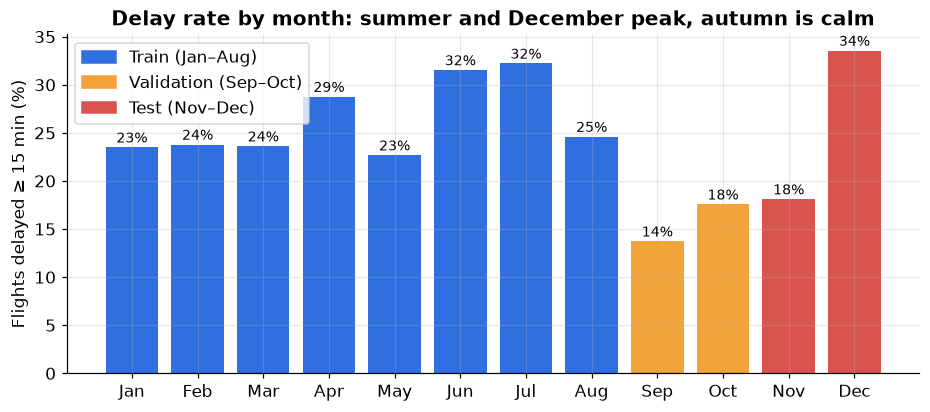

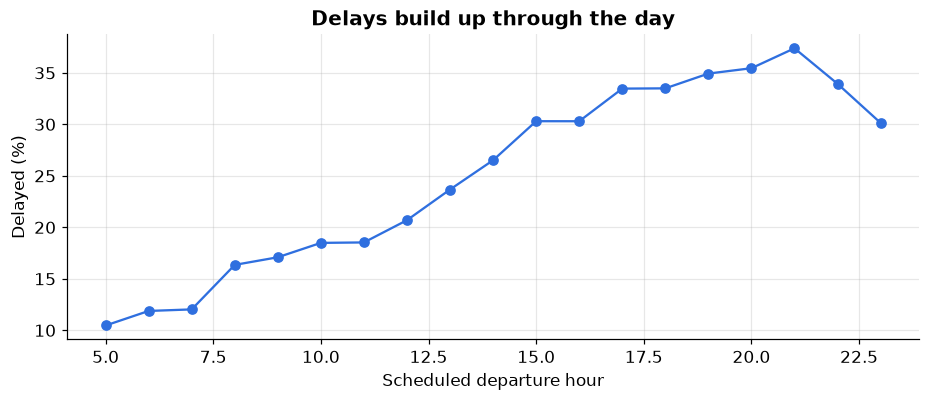

In [4]:
monthly = lab.groupby("month").agg(rate=("y", "mean"), split=("split", "first"))
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(monthly.index, monthly["rate"] * 100, color=[COL[s] for s in monthly["split"]])
for b, r in zip(bars, monthly["rate"]):
    ax.text(b.get_x() + b.get_width() / 2, r * 100 + 0.5, f"{r:.0%}", ha="center", fontsize=9)
ax.set_xticks(range(1, 13), ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_ylabel("Flights delayed ≥ 15 min (%)")
ax.set_title("Delay rate by month: summer and December peak, autumn is calm")
handles = [plt.Rectangle((0, 0), 1, 1, color=COL[s]) for s in ["train", "validation", "test"]]
ax.legend(handles, ["Train (Jan–Aug)", "Validation (Sep–Oct)", "Test (Nov–Dec)"], loc="upper left")
save(fig, "01_delay_rate_by_month")

hourly = lab.groupby("sched_hour")["y"].mean() * 100
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(hourly.index, hourly.values, marker="o", color=COL["network"])
ax.set_xlabel("Scheduled departure hour")
ax.set_ylabel("Delayed (%)")
ax.set_title("Delays build up through the day")
save(fig, "02_delay_rate_by_hour")

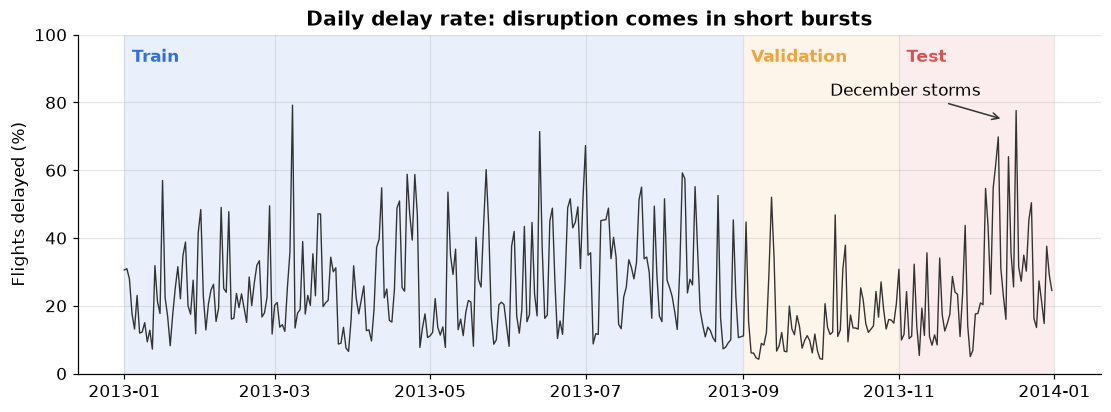

In [5]:
daily = lab.groupby("date")["y"].mean() * 100
fig, ax = plt.subplots(figsize=(12, 4))
for s, (a, b) in {"train": ("2013-01-01", "2013-08-31"), "validation": ("2013-09-01", "2013-10-31"),
                  "test": ("2013-11-01", "2013-12-31")}.items():
    ax.axvspan(pd.Timestamp(a), pd.Timestamp(b) + pd.Timedelta(days=1), color=COL[s], alpha=0.10, lw=0)
    ax.text(pd.Timestamp(a) + pd.Timedelta(days=3), 92, s.capitalize(), color=COL[s], fontweight="bold")
ax.plot(daily.index, daily.values, color="#333", lw=0.9)
ax.annotate("December storms", xy=(pd.Timestamp("2013-12-12"), 75), xytext=(pd.Timestamp("2013-10-05"), 82),
            arrowprops=dict(arrowstyle="->", color="#333"))
ax.set_ylim(0, 100)
ax.set_ylabel("Flights delayed (%)")
ax.set_title("Daily delay rate: disruption comes in short bursts")
save(fig, "03_daily_delay_rate")

## 4. Leakage-safe history tables

Each past flight is added to the **observation day in which its outcome became known**. For every origin airport and every route we store daily sums (scheduled, cancelled, completed, delayed flights and total arrival delay). A flight on day D then reads days D−3 … D−1, which are complete at 6 PM on D−1.

The schematic below shows what the model is allowed to see.

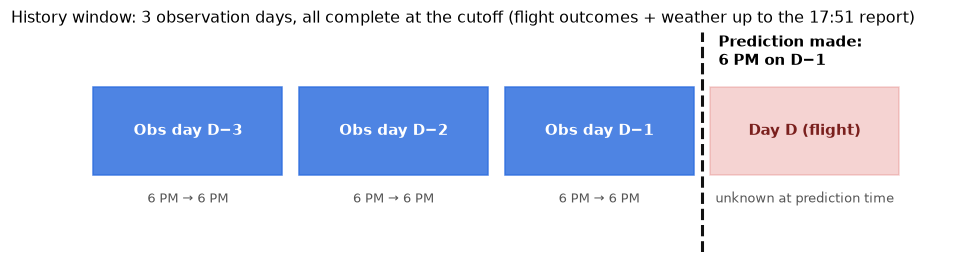

In [6]:
fig, ax = plt.subplots(figsize=(11, 2.6))
ax.set_xlim(-0.5, 5.2); ax.set_ylim(0, 2.0); ax.axis("off")
labels = ["Obs day D−3", "Obs day D−2", "Obs day D−1", "Day D (flight)"]
for i, lab_ in enumerate(labels):
    known = i < 3
    ax.add_patch(plt.Rectangle((i * 1.25, 0.7), 1.15, 0.8, color=COL["network"] if known else COL["test"],
                               alpha=0.85 if known else 0.25))
    ax.text(i * 1.25 + 0.575, 1.1, lab_, ha="center", va="center",
            color="white" if known else "#7a1f1d", fontweight="bold", fontsize=10)
    ax.text(i * 1.25 + 0.575, 0.45, "6 PM → 6 PM" if known else "unknown at prediction time",
            ha="center", fontsize=8.5, color="#555")
ax.axvline(3 * 1.25 - 0.05, color="#111", lw=2, ls="--")
ax.text(3 * 1.25 + 0.05, 1.7, "Prediction made:\n6 PM on D−1", ha="left", fontweight="bold", fontsize=10)
ax.set_title("History window: 3 observation days, all complete at the cutoff (flight outcomes + weather up to the 17:51 report)",
             fontsize=10.5, fontweight="normal", loc="left")
save(fig, "04_prediction_cutoff_schematic")

In [7]:
@dataclass
class DailyTable:
    keys: list
    columns: list
    values: np.ndarray            # [entities, PAD + N_DAYS, features]

    def index_of(self, names):
        return names.map({k: i for i, k in enumerate(self.keys)}).to_numpy()

    def window(self, ent, day, w):
        # rows of observation days day-w .. day-1 for each flight
        offs = (day + PAD - w)[:, None] + np.arange(w)[None, :]
        return self.values[ent[:, None], offs]


def dense(frame, key, cols, fill=0.0):
    keys = sorted(frame[key].dropna().unique())
    vals = np.full((len(keys), PAD + N_DAYS, len(cols)), fill)
    f = frame[frame["day"].between(0, N_DAYS - 1)]
    vals[f[key].map({k: i for i, k in enumerate(keys)}).to_numpy(), f["day"].to_numpy() + PAD] = \
        f[cols].to_numpy(dtype=float)
    return DailyTable(keys, cols, vals)


CLIP = (-60.0, 300.0)   # arrival-delay clip for daily means
sched = df.assign(day=obs_day(df["sched_dep"])).groupby(["origin", "day"]).size().rename("n_sched")
known = df[df["known_obs_day"].notna()].assign(
    day=lambda x: x["known_obs_day"].astype(int),
    cancel=lambda x: x["status"].eq("cancelled").astype(int),
    done=lambda x: x["status"].eq("arrived").astype(int),
    delayed=lambda x: x["y"].fillna(0).astype(int),
    arr=lambda x: x["arr_delay"].clip(*CLIP).fillna(0.0))
g = known.groupby(["origin", "day"])
origin_frame = pd.concat([sched, pd.DataFrame({
    "n_cancel": g["cancel"].sum(), "n_done": g["done"].sum(),
    "n_delayed": g["delayed"].sum(), "sum_arr_delay": g["arr"].sum()})], axis=1).fillna(0).reset_index()
ORIGIN = dense(origin_frame, "origin", ["n_sched", "n_cancel", "n_done", "n_delayed", "sum_arr_delay"])

arrived = df[df["status"].eq("arrived")].assign(
    day=lambda x: x["known_obs_day"].astype(int), delayed=lambda x: x["y"].astype(int),
    arr=lambda x: x["arr_delay"].clip(*CLIP))
g = arrived.groupby(["route", "day"])
ROUTE = dense(pd.DataFrame({"n_done": g.size(), "n_delayed": g["delayed"].sum(),
                            "sum_arr_delay": g["arr"].sum()}).reset_index(),
              "route", ["n_done", "n_delayed", "sum_arr_delay"])
print("origin table", ORIGIN.values.shape, "| route table", ROUTE.values.shape)

origin table (3, 379, 5) | route table (223, 379, 3)


## 5. Weather known by the cutoff

`weather.csv` has one report per hour (taken at about hh:51). Its `hour` column is **local** time, so we join on origin + local date + hour and never on `time_hour` (which is UTC). Hour 17 is known before 6 PM; hour 18 is not, so it belongs to the next observation day.

Per origin and observation day we compute 15 summaries. Missing hours are **not** forward-filled, because that would count the same rain twice.

In [8]:
w = weather_raw.drop(columns=["time_hour"])                        # UTC: never join on it
w["ts"] = pd.to_datetime(w[["year", "month", "day"]]) + pd.to_timedelta(w["hour"], unit="h")
w = w.sort_values(["origin", "ts"]).drop_duplicates(["origin", "ts"], keep="last")   # DST duplicates
for c in ["wind_speed", "wind_gust"]:
    w.loc[w[c] > 100, c] = np.nan                                  # one 1,048 mph source error
w["precip"] = w["precip"].fillna(0.0)
w["rain"] = (w["precip"] > 0).astype(float)
w["snow_risk"] = ((w["precip"] > 0) & (w["temp"] <= 32)).astype(float)
w.loc[w["temp"].isna(), "snow_risk"] = np.nan
w["low_vis"] = (w["visib"] < 3).astype(float)
w["gust"] = w["wind_gust"].notna().astype(float)
calm = w["wind_speed"].fillna(0) <= 0
w["dir_sin"] = np.where(calm, np.nan, np.sin(np.deg2rad(w["wind_dir"])))
w["dir_cos"] = np.where(calm, np.nan, np.cos(np.deg2rad(w["wind_dir"])))
w["obs_day"] = obs_day(w["ts"])


def pressure_change(s):
    s = s.dropna()
    return float(s.iloc[-1] - s.iloc[0]) if len(s) >= 2 else np.nan


g = w.sort_values("ts").groupby(["origin", "obs_day"])
wd = pd.DataFrame({
    "w_obs_hours": g.size(), "w_precip_sum": g["precip"].sum(), "w_precip_hours": g["rain"].sum(),
    "w_snow_risk_hours": g["snow_risk"].sum(), "w_visib_min": g["visib"].min(),
    "w_low_vis_hours": g["low_vis"].sum(), "w_wind_max": g["wind_speed"].max(),
    "w_gust_any": g["gust"].max(), "w_temp_min": g["temp"].min(), "w_temp_max": g["temp"].max(),
    "w_humid_mean": g["humid"].mean(), "w_pressure_min": g["pressure"].min(),
    "w_pressure_change": g["pressure"].apply(pressure_change),
    "w_wind_dir_sin": g["dir_sin"].mean(), "w_wind_dir_cos": g["dir_cos"].mean(),
}).reset_index().rename(columns={"obs_day": "day"})
WEATHER_COLS = [c for c in wd.columns if c.startswith("w_")]
wd = wd[wd["day"].between(0, N_DAYS - 1)]

WEATHER = DailyTable(ORIGIN.keys, WEATHER_COLS, np.full((len(ORIGIN.keys), PAD + N_DAYS, len(WEATHER_COLS)), np.nan))
WEATHER.values[wd["origin"].map({k: i for i, k in enumerate(ORIGIN.keys)}).to_numpy(),
               wd["day"].to_numpy() + PAD] = wd[WEATHER_COLS].to_numpy(dtype=float)
print(f"{len(WEATHER_COLS)} daily weather features per origin and observation day")
wd.head(3)

15 daily weather features per origin and observation day


,origin,day,w_obs_hours,w_precip_sum,w_precip_hours,w_snow_risk_hours,w_visib_min,w_low_vis_hours,w_wind_max,w_gust_any,w_temp_min,w_temp_max,w_humid_mean,w_pressure_min,w_pressure_change,w_wind_dir_sin,w_wind_dir_cos
0,EWR,0,16,0.0,0.0,0.0,10.0,0.0,16.11092,1.0,35.96,41.00,60.355000,1010.8,1.2,-0.884182,-0.029558
1,EWR,1,24,0.0,0.0,0.0,10.0,0.0,18.41248,1.0,24.08,33.98,47.731667,1014.1,5.6,-0.756664,0.599415
2,EWR,2,24,0.0,0.0,0.0,10.0,0.0,11.50780,1.0,26.06,33.98,54.202500,1018.7,-1.0,-0.924333,0.156914


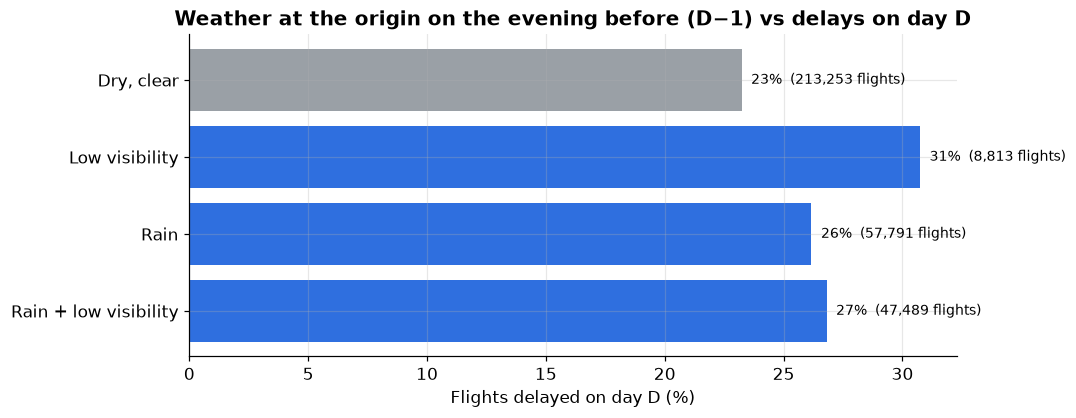

In [9]:
# Does weather on the evening before (obs day D-1) relate to delays on day D?
o_i = WEATHER.index_of(lab["origin"])
prev = WEATHER.values[o_i, lab["day_idx"].to_numpy() + PAD - 1]
rain = np.nan_to_num(prev[:, WEATHER_COLS.index("w_precip_hours")]) > 0
fog = np.nan_to_num(prev[:, WEATHER_COLS.index("w_low_vis_hours")]) > 0
cat = np.select([rain & fog, rain, fog], ["Rain + low visibility", "Rain", "Low visibility"], "Dry, clear")
order = ["Dry, clear", "Low visibility", "Rain", "Rain + low visibility"]
rates = lab.assign(cat=cat).groupby("cat")["y"].agg(["mean", "size"]).loc[order]
fig, ax = plt.subplots(figsize=(9, 3.8))
bars = ax.barh(order, rates["mean"] * 100, color=[COL["xgb"], COL["network"], COL["network"], COL["network"]])
for b, (r, n) in zip(bars, rates.values):
    ax.text(b.get_width() + 0.4, b.get_y() + b.get_height() / 2, f"{r:.0%}  ({int(n):,} flights)", va="center", fontsize=9)
ax.set_xlabel("Flights delayed on day D (%)")
ax.set_title("Weather at the origin on the evening before (D−1) vs delays on day D")
ax.invert_yaxis()
save(fig, "05_weather_before_cutoff_vs_delay")

## 6. Sequence inputs for each flight

Each flight gets two small sequences of **3 daily steps** (D−3, D−2, D−1):

- **Origin** (22 values per day): log scheduled, cancellation share, log completed, delay rate, mean delay, 15 weather summaries, a weather-observed flag, a has-data flag.
- **Route** (4 values per day): log completed, delay rate, mean delay, a has-data flag.

Each value is standardised with statistics from **training days only**. Missing values become 0 (the training mean), and flags tell the network when a zero means "no information".

In [10]:
TRAIN_LAST_DAY = 242      # 31 Aug


def safe_div(a, b):
    return np.divide(a, b, out=np.zeros_like(a, dtype=float), where=b > 0)


def standardise(x, n_flags):
    tr = x[:, PAD:PAD + TRAIN_LAST_DAY + 1].reshape(-1, x.shape[-1])
    n = x.shape[-1] - n_flags
    mean, std = np.nanmean(tr[:, :n], axis=0), np.nanstd(tr[:, :n], axis=0)
    std[std == 0] = 1.0
    out = x.copy()
    out[..., :n] = (x[..., :n] - mean) / std
    out = np.nan_to_num(out, nan=0.0)
    out[:, :PAD] = 0.0
    return out.astype(np.float32)


c = {k: ORIGIN.values[..., i] for i, k in enumerate(ORIGIN.columns)}
o_days = np.stack([np.log1p(c["n_sched"]), safe_div(c["n_cancel"], c["n_sched"]), np.log1p(c["n_done"]),
                   safe_div(c["n_delayed"], c["n_done"]), safe_div(c["sum_arr_delay"], c["n_done"])], -1)
o_has = (c["n_done"] > 0).astype(float)[..., None]
w_obs = (~np.isnan(WEATHER.values[..., 0])).astype(float)[..., None]
ORIGIN_SEQ = DailyTable(ORIGIN.keys, None, standardise(np.concatenate([o_days, WEATHER.values, w_obs, o_has], -1), 2))

c = {k: ROUTE.values[..., i] for i, k in enumerate(ROUTE.columns)}
r_days = np.stack([np.log1p(c["n_done"]), safe_div(c["n_delayed"], c["n_done"]),
                   safe_div(c["sum_arr_delay"], c["n_done"]), (c["n_done"] > 0).astype(float)], -1)
ROUTE_SEQ = DailyTable(ROUTE.keys, None, standardise(r_days, 1))

splits = {s: lab[lab["split"] == s].reset_index(drop=True) for s in ["train", "validation", "test"]}


def sequences(part):
    d = part["day_idx"].to_numpy()
    return {"origin": ORIGIN_SEQ.window(ORIGIN_SEQ.index_of(part["origin"]), d, WINDOW),
            "route": ROUTE_SEQ.window(ROUTE_SEQ.index_of(part["route"]), d, WINDOW)}


seqs = {s: sequences(p) for s, p in splits.items()}
for s in seqs:
    print(f"{s:>10}: origin {seqs[s]['origin'].shape}, route {seqs[s]['route'].shape}")

# sanity check: the last step is day D-1 (unstandardised delay rate matches a direct count)
row = splits["validation"].iloc[1000]
e, d = ORIGIN.keys.index(row["origin"]), row["day_idx"] - 1
direct = known[(known["origin"] == row["origin"]) & (known["day"] == d)]
assert np.isclose(safe_div(np.array([direct["delayed"].sum()]), np.array([direct["done"].sum()]))[0],
                  o_days[e, d + PAD, 3])
print("window alignment check passed")

     train: origin (217727, 3, 22), route (217727, 3, 4)
validation: origin (55628, 3, 22), route (55628, 3, 4)
      test: origin (53991, 3, 22), route (53991, 3, 4)
window alignment check passed


## 7. Static inputs

Carrier, origin and grouped destination become **learned embeddings**; categories seen fewer than 20 times in training share one "rare" slot. The 12 Phase 1 numeric features are standardised with training statistics.

In [11]:
CATEGORICAL = ["carrier", "origin", "dest_grouped"]
vocab = {}
for col in CATEGORICAL:
    counts = splits["train"][col].value_counts()
    vocab[col] = {v: i + 1 for i, v in enumerate(sorted(counts[counts >= 20].index))}   # 0 = rare
num_mean = splits["train"][P1_NUMERIC].to_numpy(float).mean(0)
num_std = splits["train"][P1_NUMERIC].to_numpy(float).std(0)
num_std[num_std == 0] = 1.0
CARDS = [len(vocab[c]) + 1 for c in CATEGORICAL]


@dataclass
class Batch:
    cat: torch.Tensor
    num: torch.Tensor
    seqs: dict
    y: torch.Tensor

    def __len__(self):
        return len(self.cat)

    def take(self, idx):
        return self.cat[idx], self.num[idx], {k: v[idx] for k, v in self.seqs.items()}

    def subset(self, idx):
        t = torch.from_numpy(idx)
        return Batch(self.cat[t], self.num[t], {k: v[t] for k, v in self.seqs.items()}, self.y[t])


def to_batch(part, sq):
    cat = np.stack([part[c].map(vocab[c]).fillna(0).astype(np.int64).to_numpy() for c in CATEGORICAL], 1)
    num = ((part[P1_NUMERIC].to_numpy(float) - num_mean) / num_std).astype(np.float32)
    return Batch(torch.from_numpy(cat), torch.from_numpy(num),
                 {k: torch.from_numpy(np.ascontiguousarray(v)) for k, v in sq.items()},
                 torch.from_numpy(part["y"].to_numpy(np.float32)))


data = {s: to_batch(splits[s], seqs[s]) for s in splits}
print("cardinalities:", dict(zip(CATEGORICAL, CARDS)))

cardinalities: {'carrier': 16, 'origin': 4, 'dest_grouped': 93}


## 8. The network

```
static branch : embeddings(carrier, origin, dest) + 12 numerics → Dense(64) → ReLU → Dropout
origin branch : 3 days × 22 values → GRU(32) → last hidden state
route branch  : 3 days × 4 values  → GRU(32) → last hidden state
head          : concat(64 + 32 + 32) → Dense(64) → ReLU → Dropout → 1 logit
```

In [12]:
class GRUEncoder(nn.Module):
    def __init__(self, n_in, hidden):
        super().__init__()
        self.gru = nn.GRU(n_in, hidden, batch_first=True)
        self.out_dim = hidden

    def forward(self, x):
        return self.gru(x)[1][-1]


class FlightNet(nn.Module):
    def __init__(self, cards, n_num, seq_dims, hidden=32, static_hidden=64, head_hidden=64, dropout=0.2):
        super().__init__()
        self.embs = nn.ModuleList(nn.Embedding(c, min(16, (c + 1) // 2)) for c in cards)
        emb_dim = sum(e.embedding_dim for e in self.embs)
        self.static = nn.Sequential(nn.Linear(emb_dim + n_num, static_hidden), nn.ReLU(), nn.Dropout(dropout))
        self.encoders = nn.ModuleDict({k: GRUEncoder(d, hidden) for k, d in seq_dims.items()})
        fused = static_hidden + sum(e.out_dim for e in self.encoders.values())
        self.head = nn.Sequential(nn.Linear(fused, head_hidden), nn.ReLU(), nn.Dropout(dropout))
        self.out = nn.Linear(head_hidden, 1)

    def forward(self, cat, num, seqs):
        e = torch.cat([emb(cat[:, i]) for i, emb in enumerate(self.embs)], dim=1)
        parts = [self.static(torch.cat([e, num], 1))] + [enc(seqs[k]) for k, enc in self.encoders.items()]
        return self.out(self.head(torch.cat(parts, 1))).squeeze(-1)


SEQ_DIMS = {k: v.shape[-1] for k, v in data["train"].seqs.items()}
model = FlightNet(CARDS, len(P1_NUMERIC), SEQ_DIMS, **NET)
print(model)
print(f"trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

FlightNet(
  (embs): ModuleList(
    (0): Embedding(16, 8)
    (1): Embedding(4, 2)
    (2): Embedding(93, 16)
  )
  (static): Sequential(
    (0): Linear(in_features=38, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
  )
  (encoders): ModuleDict(
    (origin): GRUEncoder(
      (gru): GRU(22, 32, batch_first=True)
    )
    (route): GRUEncoder(
      (gru): GRU(4, 32, batch_first=True)
    )
  )
  (head): Sequential(
    (0): Linear(in_features=128, out_features=64, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.2, inplace=False)
  )
  (out): Linear(in_features=64, out_features=1, bias=True)
)
trainable parameters: 21,465


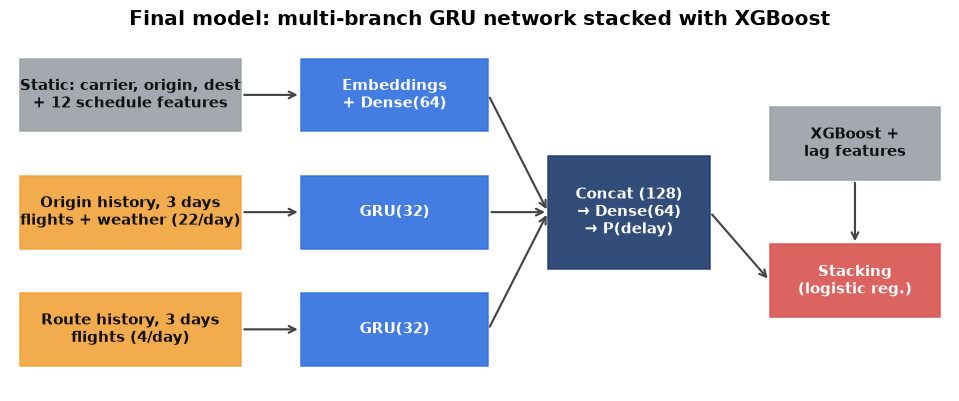

In [13]:
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.set_xlim(0, 11); ax.set_ylim(0, 4.4); ax.axis("off")


def box(x, y, w, h, text, color, tc="white"):
    ax.add_patch(plt.Rectangle((x, y), w, h, color=color, alpha=0.9))
    ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", color=tc, fontsize=9.5, fontweight="bold")


def arrow(x1, y1, x2, y2):
    ax.annotate("", xy=(x2, y2), xytext=(x1, y1), arrowprops=dict(arrowstyle="->", color="#444", lw=1.4))


box(0.1, 3.2, 2.6, 0.9, "Static: carrier, origin, dest\n+ 12 schedule features", COL["xgb"], "#111")
box(0.1, 1.75, 2.6, 0.9, "Origin history, 3 days\nflights + weather (22/day)", COL["validation"], "#111")
box(0.1, 0.3, 2.6, 0.9, "Route history, 3 days\nflights (4/day)", COL["validation"], "#111")
box(3.4, 3.2, 2.2, 0.9, "Embeddings\n+ Dense(64)", COL["network"])
box(3.4, 1.75, 2.2, 0.9, "GRU(32)", COL["network"])
box(3.4, 0.3, 2.2, 0.9, "GRU(32)", COL["network"])
box(6.3, 1.5, 1.9, 1.4, "Concat (128)\n→ Dense(64)\n→ P(delay)", COL["stacking"])
box(8.9, 2.6, 2.0, 0.9, "XGBoost +\nlag features", COL["xgb"], "#111")
box(8.9, 0.9, 2.0, 0.9, "Stacking\n(logistic reg.)", COL["test"])
for y in (3.65, 2.2, 0.75):
    arrow(2.7, y, 3.4, y)
for y in (3.65, 2.2, 0.75):
    arrow(5.6, y, 6.3, 2.2)
arrow(8.2, 2.2, 8.9, 1.35)
arrow(9.9, 2.6, 9.9, 1.8)
ax.set_title("Final model: multi-branch GRU network stacked with XGBoost")
save(fig, "06_architecture")

## 9. Training

AdamW with binary cross-entropy. After every epoch we score validation AP. Training stops after 4 epochs without improvement, and the best epoch is restored. Stage 6 showed early stopping is the regulariser that matters, because the delay pattern changes from summer to autumn.

In [14]:
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)


@torch.no_grad()
def predict(model, b, bs=8192):
    model.eval()
    return torch.cat([torch.sigmoid(model(*b.take(slice(i, i + bs)))) for i in range(0, len(b), bs)]).numpy()


def train_net(train_b, val_b, seed):
    seed_everything(seed)
    model = FlightNet(CARDS, len(P1_NUMERIC), SEQ_DIMS, **NET)
    gen = torch.Generator().manual_seed(seed)
    opt = torch.optim.AdamW(model.parameters(), lr=TRAIN["lr"], weight_decay=TRAIN["weight_decay"])
    loss_fn = nn.BCEWithLogitsLoss()
    best, history = {"ap": -1.0, "epoch": 0, "state": None}, []
    for epoch in range(1, TRAIN["max_epochs"] + 1):
        model.train()
        perm, total = torch.randperm(len(train_b), generator=gen), 0.0
        for i in range(0, len(train_b), TRAIN["batch_size"]):
            idx = perm[i:i + TRAIN["batch_size"]]
            opt.zero_grad()
            loss = loss_fn(model(*train_b.take(idx)), train_b.y[idx])
            loss.backward(); opt.step()
            total += loss.item() * len(idx)
        ap = average_precision_score(val_b.y.numpy(), predict(model, val_b))
        history.append({"epoch": epoch, "train_loss": total / len(train_b), "val_ap": ap})
        if ap > best["ap"]:
            best = {"ap": ap, "epoch": epoch, "state": copy.deepcopy(model.state_dict())}
        elif epoch - best["epoch"] >= TRAIN["patience"]:
            break
    model.load_state_dict(best["state"])
    return model, pd.DataFrame(history), best["epoch"]


nets, curves = {}, {}
for seed in SEEDS:
    t0 = time.time()
    nets[seed], curves[seed], best_epoch = train_net(data["train"], data["validation"], seed)
    print(f"seed {seed}: best epoch {best_epoch}, val AP {curves[seed]['val_ap'].max():.4f} ({time.time() - t0:.0f}s)")

seed 42: best epoch 5, val AP 0.3324 (13s)


seed 43: best epoch 4, val AP 0.3208 (7s)


seed 44: best epoch 4, val AP 0.3253 (7s)


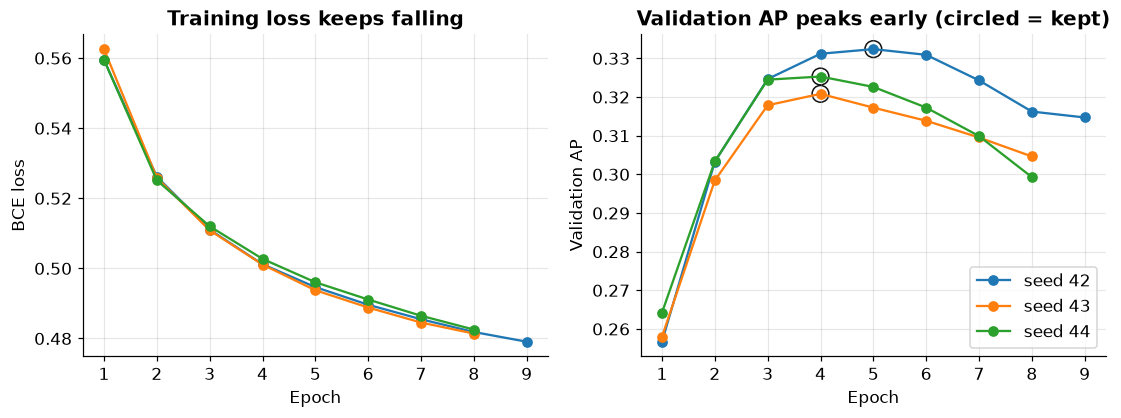

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for seed, h in curves.items():
    axes[0].plot(h["epoch"], h["train_loss"], marker="o", label=f"seed {seed}")
    axes[1].plot(h["epoch"], h["val_ap"], marker="o", label=f"seed {seed}")
    b = h["val_ap"].idxmax()
    axes[1].scatter(h.loc[b, "epoch"], h.loc[b, "val_ap"], s=120, facecolors="none", edgecolors="#111")
axes[0].set(title="Training loss keeps falling", xlabel="Epoch", ylabel="BCE loss")
axes[1].set(title="Validation AP peaks early (circled = kept)", xlabel="Epoch", ylabel="Validation AP")
axes[1].legend()
save(fig, "07_training_curves")

## 10. XGBoost on hand-made history features

The tabular partner for stacking is the Stage 0 baseline: XGBoost on the Phase 1 features plus 15 hand-made lag features (origin delay rate, mean delay and cancellation share over 1, 7 and 14 days; route delay rate, mean delay and count over 7 and 14 days). These come from the same leakage-safe daily tables.

In [16]:
def ratio(a, b):
    with np.errstate(invalid="ignore", divide="ignore"):
        return np.where(b > 0, a / np.where(b > 0, b, 1), np.nan)


def lag_features(part):
    d = part["day_idx"].to_numpy()
    oi, ri = ORIGIN.index_of(part["origin"]), ROUTE.index_of(part["route"])
    out = {}
    for w_ in (1, 7, 14):
        s = ORIGIN.window(oi, d, w_).sum(1)
        out[f"o_rate_{w_}d"] = ratio(s[:, 3], s[:, 2])
        out[f"o_mean_delay_{w_}d"] = ratio(s[:, 4], s[:, 2])
        out[f"o_cancel_share_{w_}d"] = ratio(s[:, 1], s[:, 0])
    for w_ in (7, 14):
        s = ROUTE.window(ri, d, w_).sum(1)
        out[f"r_rate_{w_}d"] = ratio(s[:, 1], s[:, 0])
        out[f"r_mean_delay_{w_}d"] = ratio(s[:, 2], s[:, 0])
        out[f"r_n_done_{w_}d"] = s[:, 0]
    return pd.DataFrame(out, index=part.index)


LAGS = [f"o_{k}_{w_}d" for w_ in (1, 7, 14) for k in ("rate", "mean_delay", "cancel_share")] + \
       [f"r_{k}_{w_}d" for w_ in (7, 14) for k in ("rate", "mean_delay", "n_done")]
tab = {s: pd.concat([p, lag_features(p)], axis=1) for s, p in splits.items()}
TAB_COLS = P1_CATEGORICAL + P1_NUMERIC + LAGS


def xgb_fit_predict(train_df, targets, seed):
    prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), P1_NUMERIC + LAGS),
        ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                          ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20))]), P1_CATEGORICAL)])
    model = XGBClassifier(n_estimators=400, max_depth=5, learning_rate=0.05, subsample=0.8,
                          colsample_bytree=0.8, objective="binary:logistic", eval_metric="logloss",
                          tree_method="hist", n_jobs=N_THREADS, random_state=seed)
    model.fit(prep.fit_transform(train_df[TAB_COLS]), train_df["y"])
    return [model.predict_proba(prep.transform(t[TAB_COLS]))[:, 1] for t in targets]


xgb_val, xgb_test = {}, {}
for seed in SEEDS:
    xgb_val[seed], xgb_test[seed] = xgb_fit_predict(tab["train"], [tab["validation"], tab["test"]], seed)
    print(f"seed {seed}: XGBoost val AP {average_precision_score(splits['validation']['y'], xgb_val[seed]):.4f}")

seed 42: XGBoost val AP 0.2417


seed 43: XGBoost val AP 0.2393


seed 44: XGBoost val AP 0.2428


## 11. Stacking (the hybrid)

Stacking learns how much to trust each model. To train it fairly, it needs predictions on rows that the models **did not train on**:

1. Split the training months into 4 blocks: Jan–Feb, Mar–Apr, May–Jun, Jul–Aug.
2. For each block, train the network and XGBoost on the other three blocks and predict that block ("out-of-fold").
3. Fit a logistic regression on the two out-of-fold logits.
4. For validation and test, feed it the predictions of the models trained on all of Jan–Aug.

In [17]:
FOLDS = [(1, 2), (3, 4), (5, 6), (7, 8)]
EPS = 1e-6
z = lambda a, b: np.column_stack([logit(np.clip(a, EPS, 1 - EPS)), logit(np.clip(b, EPS, 1 - EPS))])
months = splits["train"]["month"].to_numpy()
y_tr = splits["train"]["y"].to_numpy()

net_val = {s: predict(nets[s], data["validation"]) for s in SEEDS}
net_test = {s: predict(nets[s], data["test"]) for s in SEEDS}
stack_val, stack_test, stack_weights = {}, {}, {}
for seed in SEEDS:
    t0 = time.time()
    oof_net, oof_xgb = np.zeros(len(y_tr)), np.zeros(len(y_tr))
    for block in FOLDS:
        held = np.isin(months, block)
        fold_net, _, _ = train_net(data["train"].subset(np.where(~held)[0]), data["validation"], seed)
        oof_net[held] = predict(fold_net, data["train"].subset(np.where(held)[0]))
        oof_xgb[held] = xgb_fit_predict(tab["train"][~held], [tab["train"][held]], seed)[0]
    stack = LogisticRegression().fit(z(oof_net, oof_xgb), y_tr)
    stack_weights[seed] = stack.coef_[0]
    stack_val[seed] = stack.predict_proba(z(net_val[seed], xgb_val[seed]))[:, 1]
    stack_test[seed] = stack.predict_proba(z(net_test[seed], xgb_test[seed]))[:, 1]
    print(f"seed {seed}: weights network={stack.coef_[0][0]:.3f} xgboost={stack.coef_[0][1]:.3f} "
          f"| val AP {average_precision_score(splits['validation']['y'], stack_val[seed]):.4f} ({time.time() - t0:.0f}s)")

seed 42: weights network=0.480 xgboost=0.290 | val AP 0.3256 (43s)


seed 43: weights network=0.479 xgboost=0.272 | val AP 0.3229 (44s)


seed 44: weights network=0.594 xgboost=0.228 | val AP 0.3259 (42s)


## 12. Results

Every threshold is chosen on **validation** (best F1) and then applied unchanged to test. The test split is scored here for the first and only time. The "Phase 1" row is the logistic regression from Phase 1, for reference.

In [18]:
def f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / (prec[:-1] + rec[:-1] + 1e-12)
    return thr[int(np.argmax(f1))]


def metrics(y_val, p_val, y, p):
    thr = f1_threshold(y_val, p_val)
    pred = (p >= thr).astype(int)
    tp = int(((pred == 1) & (y == 1)).sum())
    prec, rec = tp / max(pred.sum(), 1), tp / max(y.sum(), 1)
    return {"AP": average_precision_score(y, p), "AP lift": average_precision_score(y, p) / y.mean(),
            "ROC-AUC": roc_auc_score(y, p), "Precision": prec, "Recall": rec,
            "F1": 2 * prec * rec / max(prec + rec, 1e-12),
            "Accuracy (val threshold)": (pred == y).mean(), "Accuracy (0.5)": ((p >= 0.5) == y).mean()}


# Phase 1 reference: logistic regression on the Phase 1 features
prep_lr = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)), ("scale", StandardScaler())]), P1_NUMERIC),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore", min_frequency=20))]), P1_CATEGORICAL)])
lr = Pipeline([("prep", prep_lr), ("model", LogisticRegression(max_iter=1000, random_state=42))])
lr.fit(splits["train"][P1_CATEGORICAL + P1_NUMERIC], y_tr)
lr_val, lr_test = [lr.predict_proba(splits[s][P1_CATEGORICAL + P1_NUMERIC])[:, 1] for s in ("validation", "test")]

mean = lambda d: np.mean([d[s] for s in SEEDS], axis=0)     # average of the 3 seeds
MODELS = {"Stacking (final)": (mean(stack_val), mean(stack_test), COL["stacking"]),
          "GRU network": (mean(net_val), mean(net_test), COL["network"]),
          "XGBoost + lags": (mean(xgb_val), mean(xgb_test), COL["xgb"]),
          "Phase 1 logistic regression": (lr_val, lr_test, COL["lr"])}
y_val, y_test = splits["validation"]["y"].to_numpy(), splits["test"]["y"].to_numpy()

rows = []
for name, (pv, pt, _) in MODELS.items():
    rows.append({"model": name, "split": "validation", **metrics(y_val, pv, y_val, pv)})
    rows.append({"model": name, "split": "test", **metrics(y_val, pv, y_test, pt)})
results = pd.DataFrame(rows)
print(f"delayed share: validation {y_val.mean():.1%}, test {y_test.mean():.1%} "
      f"(so 'always on time' has accuracy {1 - y_test.mean():.1%} on test)")
results.pivot(index="model", columns="split", values=["AP", "ROC-AUC", "F1"]).round(4).loc[list(MODELS)]

delayed share: validation 15.7%, test 25.8% (so 'always on time' has accuracy 74.2% on test)


AP            ROC-AUC                 F1  \
split                          test validation    test validation    test   
model                                                                       
Stacking (final)             0.3603     0.3293  0.6313     0.6930  0.3661   
GRU network                  0.3514     0.3318  0.6172     0.6894  0.3367   
XGBoost + lags               0.3579     0.2449  0.6323     0.6527  0.4271   
Phase 1 logistic regression  0.3361     0.2349  0.6071     0.6449  0.3846   

                                        
split                       validation  
model                                   
Stacking (final)                0.3670  
GRU network                     0.3665  
XGBoost + lags                  0.3334  
Phase 1 logistic regression     0.3267

In [19]:
results[results["split"] == "test"].drop(columns="split").set_index("model").round(4)

,AP,AP lift,ROC-AUC,Precision,Recall,F1,Accuracy (val threshold),Accuracy (0.5)
model,,,,,,,,
Stacking (final),0.3603,1.3947,0.6313,0.3762,0.3566,0.3661,0.6811,0.7423
GRU network,0.3514,1.3603,0.6172,0.3750,0.3055,0.3367,0.6891,0.7406
XGBoost + lags,0.3579,1.3858,0.6323,0.3384,0.5787,0.4271,0.5990,0.7395
Phase 1 logistic regression,0.3361,1.3014,0.6071,0.3410,0.4410,0.3846,0.6355,0.7384


In [20]:
per_seed = pd.DataFrame({
    "GRU network": [average_precision_score(y_test, net_test[s]) for s in SEEDS],
    "XGBoost + lags": [average_precision_score(y_test, xgb_test[s]) for s in SEEDS],
    "Stacking (final)": [average_precision_score(y_test, stack_test[s]) for s in SEEDS]}, index=SEEDS)
print("Test AP per seed (mean ± std):")
print(per_seed.agg(["mean", "std"]).round(4).T)

Test AP per seed (mean ± std):
                    mean     std
GRU network       0.3486  0.0059
XGBoost + lags    0.3558  0.0028
Stacking (final)  0.3586  0.0050


### Figures: comparing the models

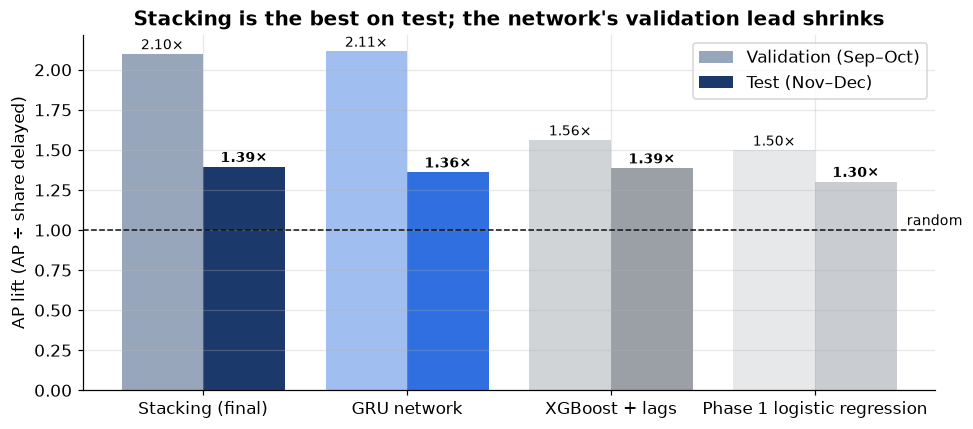

In [21]:
fig, ax = plt.subplots(figsize=(10, 4.2))
names = list(MODELS)
xpos = np.arange(len(names))
val_ap = [results.query("model == @n and split == 'validation'")["AP lift"].item() for n in names]
test_ap = [results.query("model == @n and split == 'test'")["AP lift"].item() for n in names]
ax.bar(xpos - 0.2, val_ap, 0.4, color=[MODELS[n][2] for n in names], alpha=0.45, label="Validation (Sep–Oct)")
ax.bar(xpos + 0.2, test_ap, 0.4, color=[MODELS[n][2] for n in names], label="Test (Nov–Dec)")
for x_, v, t in zip(xpos, val_ap, test_ap):
    ax.text(x_ - 0.2, v + 0.03, f"{v:.2f}×", ha="center", fontsize=9)
    ax.text(x_ + 0.2, t + 0.03, f"{t:.2f}×", ha="center", fontsize=9, fontweight="bold")
ax.axhline(1, color="#111", lw=1, ls="--")
ax.text(len(names) - 0.55, 1.03, "random", fontsize=9)
ax.set_xticks(xpos, names)
ax.set_ylabel("AP lift (AP ÷ share delayed)")
ax.set_title("Stacking is the best on test; the network's validation lead shrinks")
ax.legend()
save(fig, "08_ap_lift_validation_vs_test")

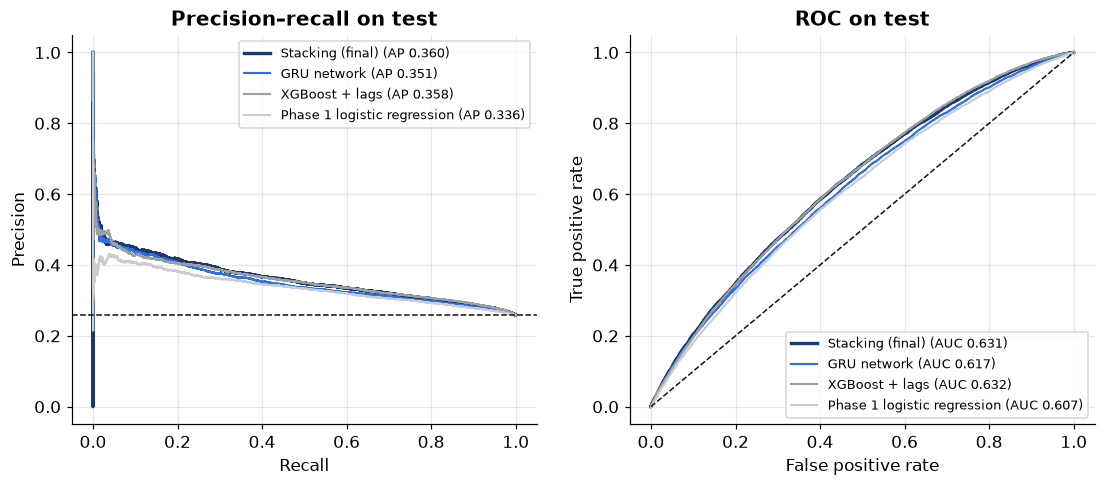

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
for name, (_, pt, color) in MODELS.items():
    p, r, _ = precision_recall_curve(y_test, pt)
    axes[0].plot(r, p, color=color, lw=2.2 if "Stacking" in name else 1.4,
                 label=f"{name} (AP {average_precision_score(y_test, pt):.3f})")
    fpr, tpr, _ = roc_curve(y_test, pt)
    axes[1].plot(fpr, tpr, color=color, lw=2.2 if "Stacking" in name else 1.4,
                 label=f"{name} (AUC {roc_auc_score(y_test, pt):.3f})")
axes[0].axhline(y_test.mean(), color="#111", ls="--", lw=1)
axes[0].set(title="Precision–recall on test", xlabel="Recall", ylabel="Precision")
axes[1].plot([0, 1], [0, 1], color="#111", ls="--", lw=1)
axes[1].set(title="ROC on test", xlabel="False positive rate", ylabel="True positive rate")
for a in axes:
    a.legend(fontsize=8.5, loc="upper right" if a is axes[0] else "lower right")
save(fig, "09_pr_and_roc_test")

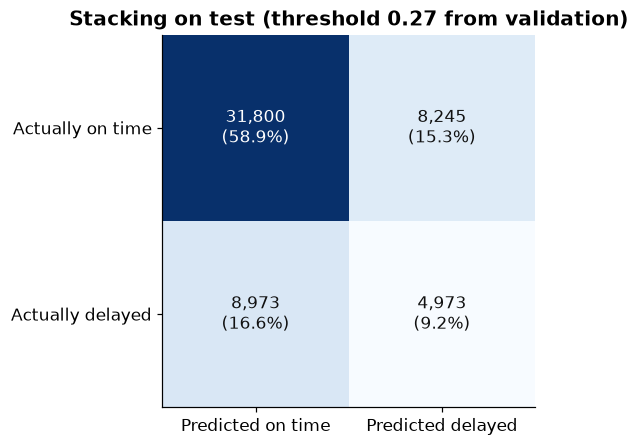

In [23]:
pv, pt, _ = MODELS["Stacking (final)"]
thr = f1_threshold(y_val, pv)
cm = confusion_matrix(y_test, (pt >= thr).astype(int))
fig, ax = plt.subplots(figsize=(5.2, 4.4))
ax.imshow(cm, cmap="Blues")
ax.grid(False)
for (i, j), v in np.ndenumerate(cm):
    ax.text(j, i, f"{v:,}\n({v / cm.sum():.1%})", ha="center", va="center",
            color="white" if v > cm.max() / 2 else "#111", fontsize=11)
ax.set_xticks([0, 1], ["Predicted on time", "Predicted delayed"])
ax.set_yticks([0, 1], ["Actually on time", "Actually delayed"])
ax.set_title(f"Stacking on test (threshold {thr:.2f} from validation)")
save(fig, "10_confusion_matrix_test")

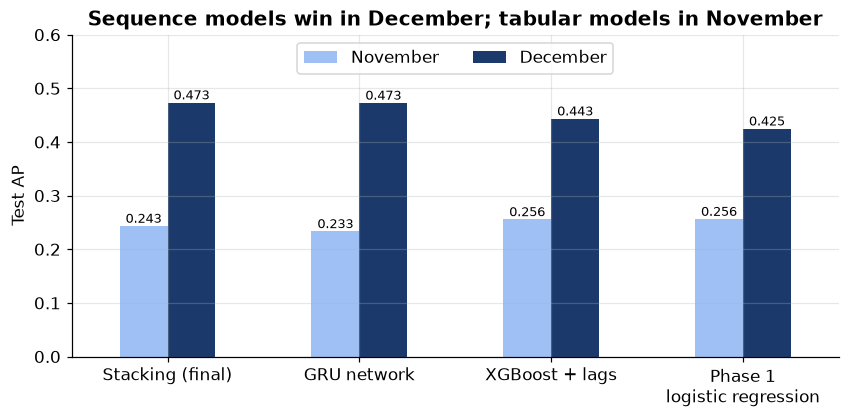

,Stacking (final),GRU network,XGBoost + lags,Phase 1 logistic regression
November,0.2435,0.2335,0.2558,0.2563
December,0.4735,0.4729,0.4435,0.4248


In [24]:
test = splits["test"].assign(**{n: MODELS[n][1] for n in MODELS})
by_month = pd.DataFrame({n: [average_precision_score(g["y"], g[n]) for _, g in test.groupby("month")]
                         for n in MODELS}, index=["November", "December"])
fig, ax = plt.subplots(figsize=(9, 3.8))
by_month.T.plot.bar(ax=ax, color=["#9fc0f5", "#1b3a6b"], rot=0)
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.3f", fontsize=8.5)
ax.set_xticklabels([n.replace(" logistic", "\nlogistic") for n in by_month.columns])
ax.set_ylim(0, 0.6)
ax.legend(loc="upper center", ncol=2)
ax.set_ylabel("Test AP")
ax.set_title("Sequence models win in December; tabular models in November")
save(fig, "11_test_ap_by_month")
by_month.round(4)

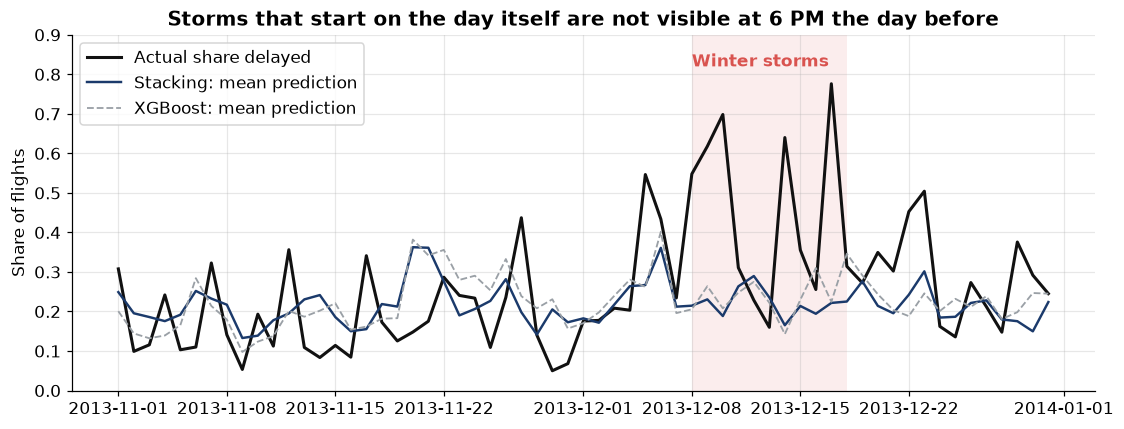

In [25]:
day_view = test.groupby("date").agg(actual=("y", "mean"), network=("GRU network", "mean"),
                                    xgb=("XGBoost + lags", "mean"), stacking=("Stacking (final)", "mean"))
fig, ax = plt.subplots(figsize=(12, 4.2))
ax.axvspan(pd.Timestamp("2013-12-08"), pd.Timestamp("2013-12-18"), color=COL["test"], alpha=0.1, lw=0)
ax.text(pd.Timestamp("2013-12-08"), 0.82, "Winter storms", color=COL["test"], fontweight="bold")
ax.plot(day_view.index, day_view["actual"], color="#111", lw=2, label="Actual share delayed")
ax.plot(day_view.index, day_view["stacking"], color=COL["stacking"], lw=1.6, label="Stacking: mean prediction")
ax.plot(day_view.index, day_view["xgb"], color=COL["xgb"], lw=1.2, ls="--", label="XGBoost: mean prediction")
ax.set_ylim(0, 0.9)
ax.set_ylabel("Share of flights")
ax.set_title("Storms that start on the day itself are not visible at 6 PM the day before")
ax.legend(loc="upper left")
save(fig, "12_test_daily_actual_vs_predicted")

## 13. How we got here

The final model is the result of eight experiment stages. Each was decided on validation, with 3 seeds per configuration. The numbers below come from the experiment log (`experiments/results.csv`); the full reasoning is in `DECISIONS.md`.

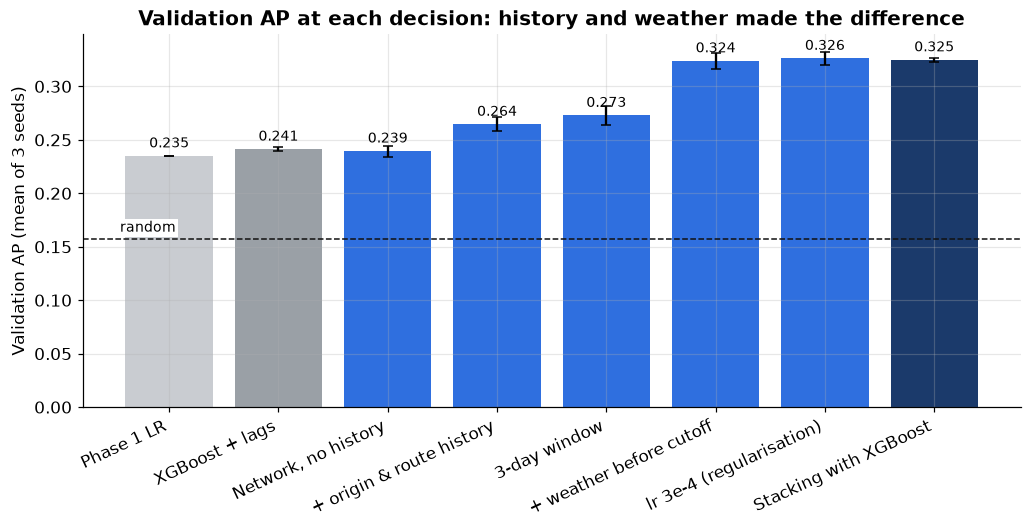

,step,val_ap,std
0,Phase 1 LR,0.2349,NaN
1,XGBoost + lags,0.2413,0.0018
2,"Network, no history",0.2394,0.0052
3,+ origin & route history,0.2645,0.0066
4,3-day window,0.2728,0.0092
5,+ weather before cutoff,0.3238,0.0078
6,lr 3e-4 (regularisation),0.3262,0.0058
7,Stacking with XGBoost,0.3248,0.0017


In [26]:
log = pd.read_csv(ROOT / "experiments" / "results.csv")
log["stage"] = log["stage"].astype(str)
steps = [("Phase 1 LR", "0", "phase1_features", "logreg"),
         ("XGBoost + lags", "0", "phase1_plus_lags", "xgboost"),
         ("Network, no history", "1", "static_only", None),
         ("+ origin & route history", "1", "origin_route", None),
         ("3-day window", "2", "window_3d", None),
         ("+ weather before cutoff", "3", "daily_weather", None),
         ("lr 3e-4 (regularisation)", "6", "lr_3e-4", None),
         ("Stacking with XGBoost", "7", "B_stacking", None)]
vals = []
for label, st, exp, mdl in steps:
    sel = log[(log["stage"] == st) & (log["experiment"] == exp)]
    if mdl:
        sel = sel[sel["model"] == mdl]
    vals.append((label, sel["val_ap"].mean(), sel["val_ap"].std()))
journey = pd.DataFrame(vals, columns=["step", "val_ap", "std"])
fig, ax = plt.subplots(figsize=(11, 4.4))
colors = [COL["lr"], COL["xgb"]] + [COL["network"]] * 5 + [COL["stacking"]]
ax.bar(journey["step"], journey["val_ap"], yerr=journey["std"].fillna(0), color=colors, capsize=3)
for i, v in enumerate(journey["val_ap"]):
    ax.text(i, v + 0.008, f"{v:.3f}", ha="center", fontsize=9)
ax.axhline(y_val.mean(), color="#111", ls="--", lw=1)
ax.text(-0.45, y_val.mean() + 0.004, "random", fontsize=9, ha="left", va="bottom", bbox=dict(fc="white", ec="none", pad=1))
ax.set_ylabel("Validation AP (mean of 3 seeds)")
ax.set_title("Validation AP at each decision: history and weather made the difference")
plt.setp(ax.get_xticklabels(), rotation=25, ha="right")
save(fig, "13_journey_validation_ap")
journey.round(4)

## 14. Conclusions

- **Final model:** a multi-branch GRU network (3-day origin and route history, with weather known by 6 PM on D−1) **stacked with XGBoost**. On the unseen test months it is the best of the models compared, by test AP.
- **What made the difference:** reading recent history as a sequence (+0.025 validation AP over the same network without history) and weather observed before the cutoff (+0.051). Encoder type, category encoding and regularisation mattered much less.
- **Why stacking:** the network is strongest when disruption carries over from the previous evening (December). XGBoost is steadier on ordinary days (November). The stacker gives the network about twice XGBoost's weight.
- **Limits:**
  - Storms that begin on the day itself are invisible at the cutoff, so the model under-predicts those days.
  - The validation months had no snow, so validation scores were optimistic.
  - Accuracy (~74%) is not informative here, because 74% of test flights are on time.
- **Next step:** weather **forecasts** issued before the cutoff. A perfect-forecast experiment (upper bound, Stage 3) suggests they would add more than any architecture change.

All figures are saved in `figures/phase2/` for the presentation.